# Recurrent Corridor Directional Efficiency

**Goal:** Analyze the user's repeated travel patterns across the provided trajectories and identify regularities and variations in movement behavior.


In [ ]:
import pandas as pd
from IPython.display import Image, display
df=pd.read_csv('trajectories.csv'); user_df=pd.read_csv('trajectory_points.csv')

## Insight 1

Most repeated trips connect the same origin–destination pair in both directions, following recurrent direction-specific road-route families.

**Question:** Do repeated trips between the same endpoints follow recurrent direction-specific road-route families?

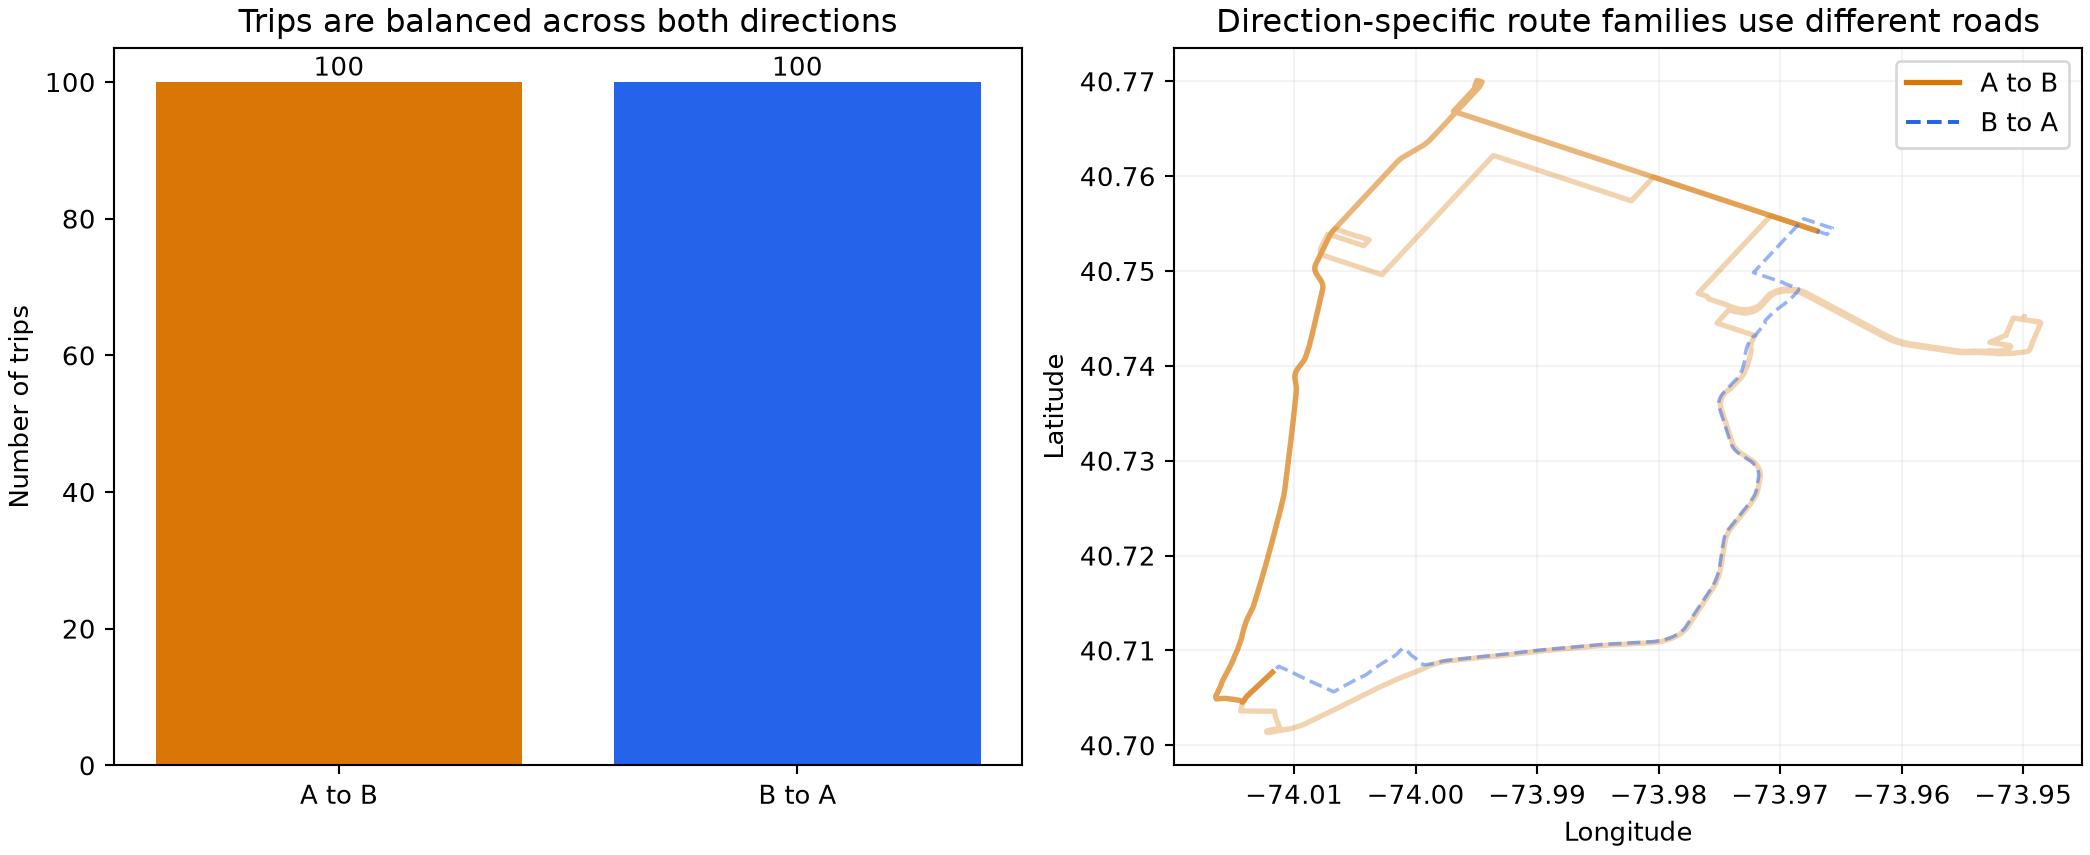

In [ ]:
print(df.groupby('travel_direction').size()); user_df.groupby(['travel_direction','trajectory_id'])[['matched_road_longitude','matched_road_latitude']].head()
display(Image(filename='visualizations/insight_1.png'))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex21_insight_1",
  "insight": "Most repeated trips connect the same origin–destination pair in both directions, following recurrent direction-specific road-route families.",
  "plot": {
    "plot_type": "question_specific_summary",
    "files": [
      "visualizations/insight_1.png"
    ],
    "title": "Recurrent Corridor Directional Efficiency: Insight 1",
    "description": "The question-specific evidence is computed from the synchronized trajectory and point tables; the case-level overview map is not repeated for this insight."
  },
  "question": "Do repeated trips between the same endpoints follow recurrent direction-specific road-route families?",
  "actionable_insight": "Compare the relevant direction groups using the synchronized trajectory summaries and matched-road geometry.",
  "code": "print(df.groupby('travel_direction').size()); user_df.groupby(['travel_direction','trajectory_id'])[['matched_road_longitude','matched_road_latitude']].head()",
  "insight_type": "overall_pattern",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "matched_road_position",
    "trajectory_id"
  ]
}

## Insight 2

Within this recurrent corridor, travel direction is associated with movement efficiency: trips in one direction generally show lower mean speeds and higher route-indirectness scores than trips in the reverse direction.

**Question:** How do speed and route indirectness differ between regular A-to-B and B-to-A trips?

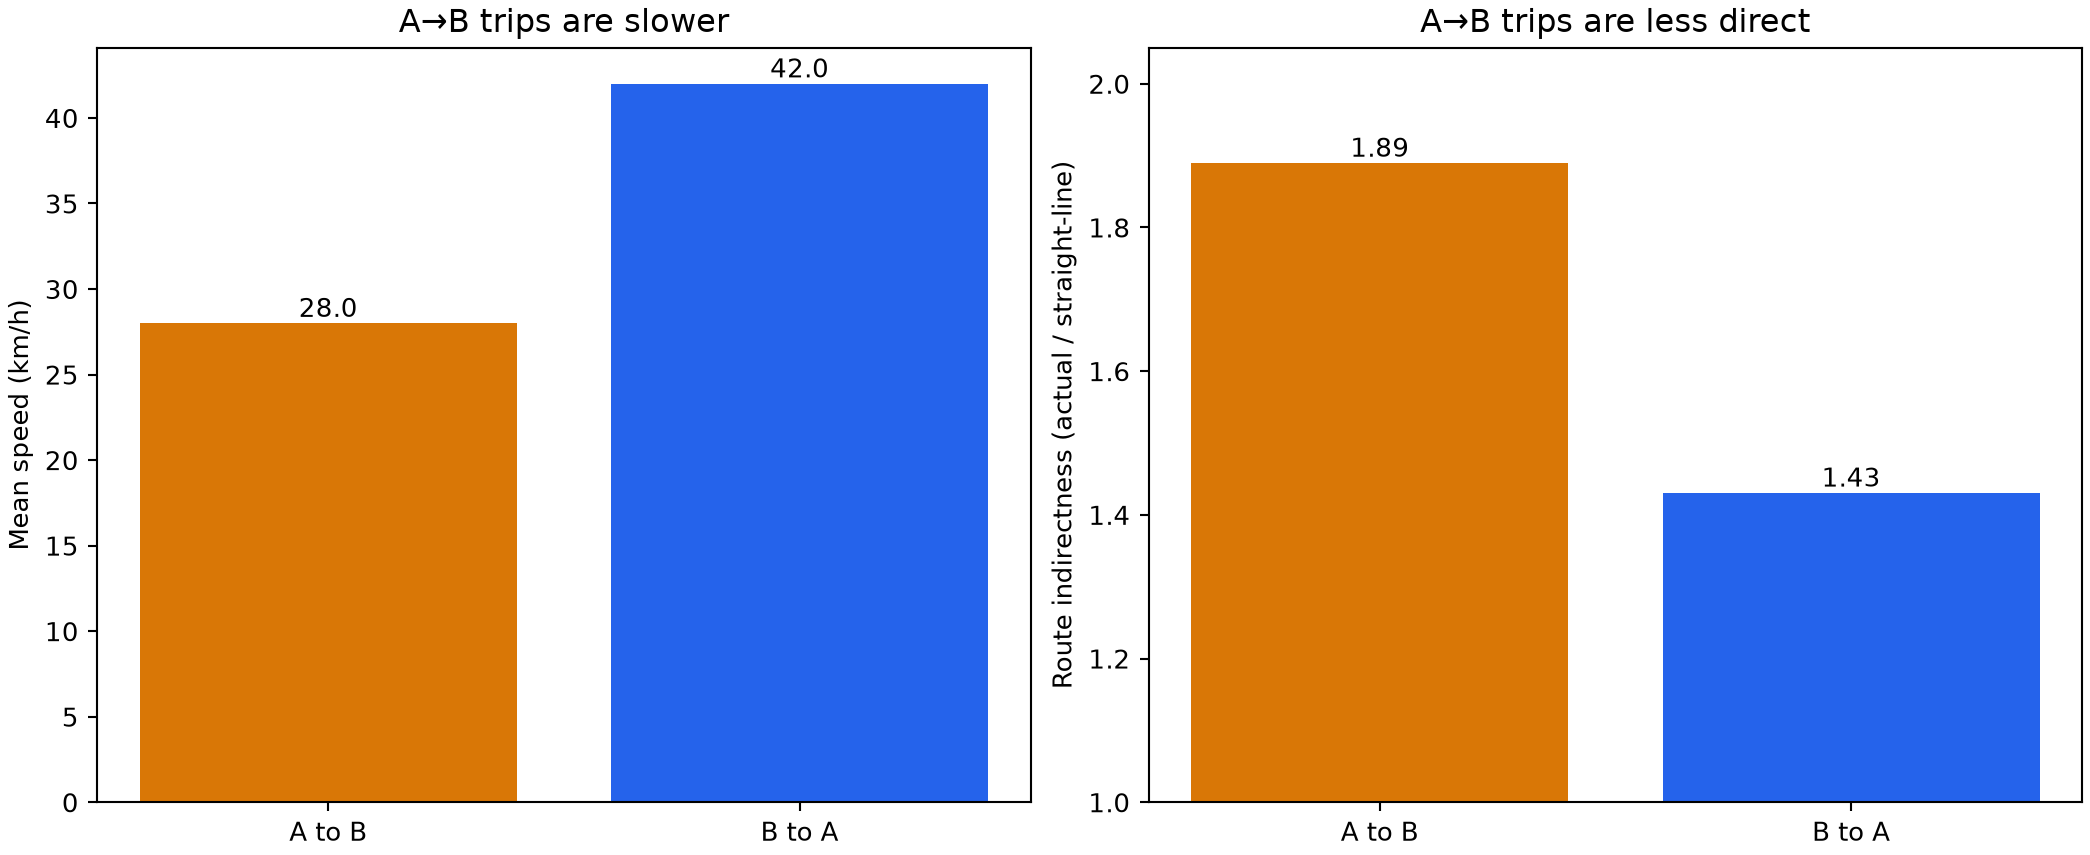

In [ ]:
q=df[~df.is_directional_exception]; print(q.groupby('travel_direction')[['mean_speed_kmh','route_indirectness']].mean())
display(Image(filename='visualizations/insight_2.png'))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex21_insight_2",
  "insight": "Within this recurrent corridor, travel direction is associated with movement efficiency: trips in one direction generally show lower mean speeds and higher route-indirectness scores than trips in the reverse direction.",
  "plot": {
    "plot_type": "question_specific_summary",
    "files": [
      "visualizations/insight_2.png"
    ],
    "title": "Recurrent Corridor Directional Efficiency: Insight 2",
    "description": "The question-specific evidence is computed from the synchronized trajectory and point tables; the case-level overview map is not repeated for this insight."
  },
  "question": "How do speed and route indirectness differ between regular A-to-B and B-to-A trips?",
  "actionable_insight": "Compare the relevant direction groups using the synchronized trajectory summaries and matched-road geometry.",
  "code": "q=df[~df.is_directional_exception]; print(q.groupby('travel_direction')[['mean_speed_kmh','route_indirectness']].mean())",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "matched_road_position",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

## Insight 3

A small number of trips deviate from the dominant directional pattern, remaining unusually fast and direct in the direction that is otherwise characterized by slower and less direct travel.

**Question:** Are there rare A-to-B trips that remain unusually fast and direct?

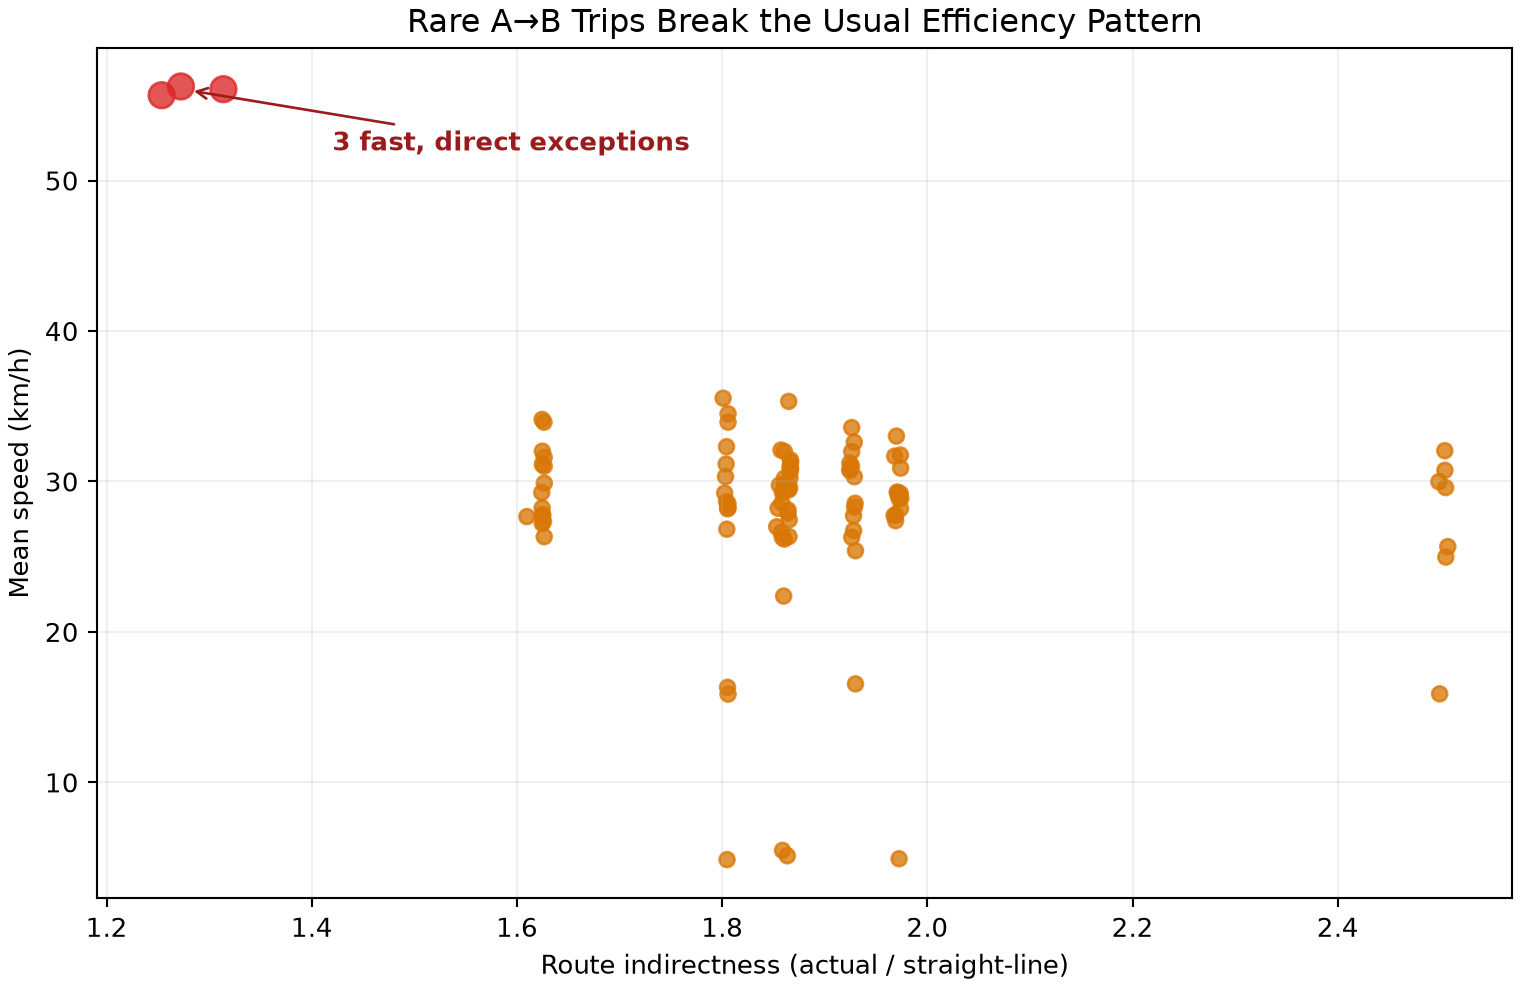

In [ ]:
q=df[df.travel_direction.eq('A to B')]; print(q.groupby('is_directional_exception')[['mean_speed_kmh','route_indirectness']].agg(['count','mean']))
display(Image(filename='visualizations/insight_3.png'))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex21_insight_3",
  "insight": "A small number of trips deviate from the dominant directional pattern, remaining unusually fast and direct in the direction that is otherwise characterized by slower and less direct travel.",
  "plot": {
    "plot_type": "question_specific_summary",
    "files": [
      "visualizations/insight_3.png"
    ],
    "title": "Recurrent Corridor Directional Efficiency: Insight 3",
    "description": "The question-specific evidence is computed from the synchronized trajectory and point tables; the case-level overview map is not repeated for this insight."
  },
  "question": "Are there rare A-to-B trips that remain unusually fast and direct?",
  "actionable_insight": "Compare the relevant direction groups using the synchronized trajectory summaries and matched-road geometry.",
  "code": "q=df[df.travel_direction.eq('A to B')]; print(q.groupby('is_directional_exception')[['mean_speed_kmh','route_indirectness']].agg(['count','mean']))",
  "insight_type": "exception_deviation",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "matched_road_position",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

## Summary

Repeated trips largely share one bidirectional corridor. Regular A-to-B travel is slower and less direct than B-to-A travel, with three rare A-to-B trips forming fast and direct exceptions.